# Compulsory Assignment 5 - Cognitive Health from Lifestyle Habits
#### Group 12
*Group Members: Kiki, Sathusan and Durga*

Assignment requirements (must use):
* Hyperparameter tuning
* Scikit-learn Pipelines
* Cross-validation
* Mean Absolute Error (MAE)
* All pipelines must contain suitale preprocessing
* At least one pipeline with linear regression e.g. multi-linear regression/polynomial regression/PCR/PLS/RANSAC/regularized regression
* Pick 2 model pipelines from A, B, C

### Imports

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

### Reading the data

In [3]:
# Read the training data
df_train = pd.read_csv("train.csv", sep=',')

df_train.head()

,id,age,sleep_duration_hrs,sleep_quality_score,cardio_mins_wk,water_intake_liters,screen_time_recreational_hrs,social_media_hrs,blood_pressure_sys,diet_ultra_processed_pct,diet_omega3_freq,smoking_status,alcohol_drinks_wk,novel_learning_hrs_wk,social_connection_score,chronic_stress_score,target
0,193355,55.0,NaN,9.0,20.0,0.900000,3.7,1.1,129.0,47.7,1.0,Never,3.0,1.8,8.0,8.0,27
1,509850,23.0,6.8,8.0,66.0,-3.634081,NaN,1.8,108.0,29.9,7.0,Never,63.0,0.9,5.0,5.0,28
2,413954,70.0,9.4,9.0,13.0,2.100000,9.5,5.0,137.0,NaN,2.0,Never,1.0,2.4,8.0,5.0,25
3,94859,40.0,7.5,10.0,200.0,1.600000,5.0,0.5,124.0,NaN,0.0,Never,7.0,0.9,NaN,8.0,29
4,18214,18.0,6.9,6.0,81.0,NaN,3.6,1.2,118.0,43.2,2.0,Never,0.0,0.5,5.0,10.0,26


In [6]:
# Read the training data
df_test = pd.read_csv("test.csv", sep=',')

df_test.head()

,id,age,sleep_duration_hrs,sleep_quality_score,cardio_mins_wk,water_intake_liters,screen_time_recreational_hrs,social_media_hrs,blood_pressure_sys,diet_ultra_processed_pct,diet_omega3_freq,smoking_status,alcohol_drinks_wk,novel_learning_hrs_wk,social_connection_score,chronic_stress_score
0,104241,60,8.2,10,69,2.3,8.3,7.1,145,93.7,3,Never,0,0.7,7,3
1,199676,65,7.2,9,97,2.5,6.8,4.8,125,25.2,3,Never,4,5.4,10,6
2,140199,47,9.1,10,217,2.6,4.2,1.7,125,79.0,2,Never,1,0.7,8,6
3,132814,53,5.7,10,47,2.7,3.4,1.7,127,56.9,0,Never,0,0.5,6,8
4,408697,37,8.4,8,36,3.0,11.1,3.9,114,51.1,0,Never,0,2.0,3,7


### Data description

The data simulates a lifestyle and health survey of adults. The target is a simulated score modeled after the Montreal Cognitive Assessment (MoCA)(integer, documented range 5 to 30). It is a baseline score minus penalties (age, stress, poor diet, smoking) plus bonuses (cardio, learning, social connection). 

### Data exploration and visualization

In [7]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 367500 entries, 0 to 367499
Data columns (total 17 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            367500 non-null  int64  
 1   age                           345653 non-null  float64
 2   sleep_duration_hrs            340323 non-null  float64
 3   sleep_quality_score           357702 non-null  float64
 4   cardio_mins_wk                355386 non-null  float64
 5   water_intake_liters           358969 non-null  float64
 6   screen_time_recreational_hrs  338865 non-null  float64
 7   social_media_hrs              362207 non-null  float64
 8   blood_pressure_sys            357789 non-null  float64
 9   diet_ultra_processed_pct      354171 non-null  float64
 10  diet_omega3_freq              344987 non-null  float64
 11  smoking_status                342146 non-null  str    
 12  alcohol_drinks_wk             346938 non-null  float64


In [8]:
df_train.describe()

,id,age,sleep_duration_hrs,sleep_quality_score,cardio_mins_wk,water_intake_liters,screen_time_recreational_hrs,social_media_hrs,blood_pressure_sys,diet_ultra_processed_pct,diet_omega3_freq,alcohol_drinks_wk,novel_learning_hrs_wk,social_connection_score,chronic_stress_score,target
count,367500.000000,345653.000000,340323.000000,357702.000000,355386.000000,358969.000000,338865.000000,362207.000000,357789.000000,354171.000000,344987.000000,346938.000000,340773.000000,342627.000000,349571.000000,367500.000000
mean,262372.901635,44.734089,7.100915,8.258727,98.868537,2.201164,5.509037,2.757720,126.222164,50.019510,1.863169,3.081012,2.268003,6.944966,5.973044,27.817293
std,151191.541515,17.178694,1.291474,1.919521,138.695219,0.715956,2.930716,2.174297,13.173230,23.564208,1.878462,6.186425,2.505047,2.275089,2.792521,1.801869
min,0.000000,-129.000000,-5.934089,-11.000000,-1300.000000,-5.009674,-24.112509,-19.159991,-7.000000,-187.354820,-17.000000,-59.000000,-23.025042,-16.000000,-22.000000,17.000000
25%,131320.750000,34.000000,6.400000,7.000000,24.000000,1.800000,3.800000,1.300000,119.000000,36.500000,1.000000,0.000000,1.000000,6.000000,4.000000,27.000000
50%,262736.500000,44.000000,7.100000,8.000000,54.000000,2.200000,5.500000,2.400000,126.000000,50.000000,2.000000,1.000000,1.600000,7.000000,6.000000,28.000000
75%,393623.250000,55.000000,7.800000,10.000000,122.000000,2.600000,7.200000,3.900000,134.000000,63.600000,3.000000,4.000000,2.800000,8.000000,8.000000,29.000000
max,517499.000000,218.000000,20.139134,28.000000,1497.000000,9.402479,35.090503,24.661864,259.000000,287.389128,21.000000,65.000000,27.562680,30.000000,34.000000,30.000000


In [9]:
df_train = df_train.drop(columns = "id")

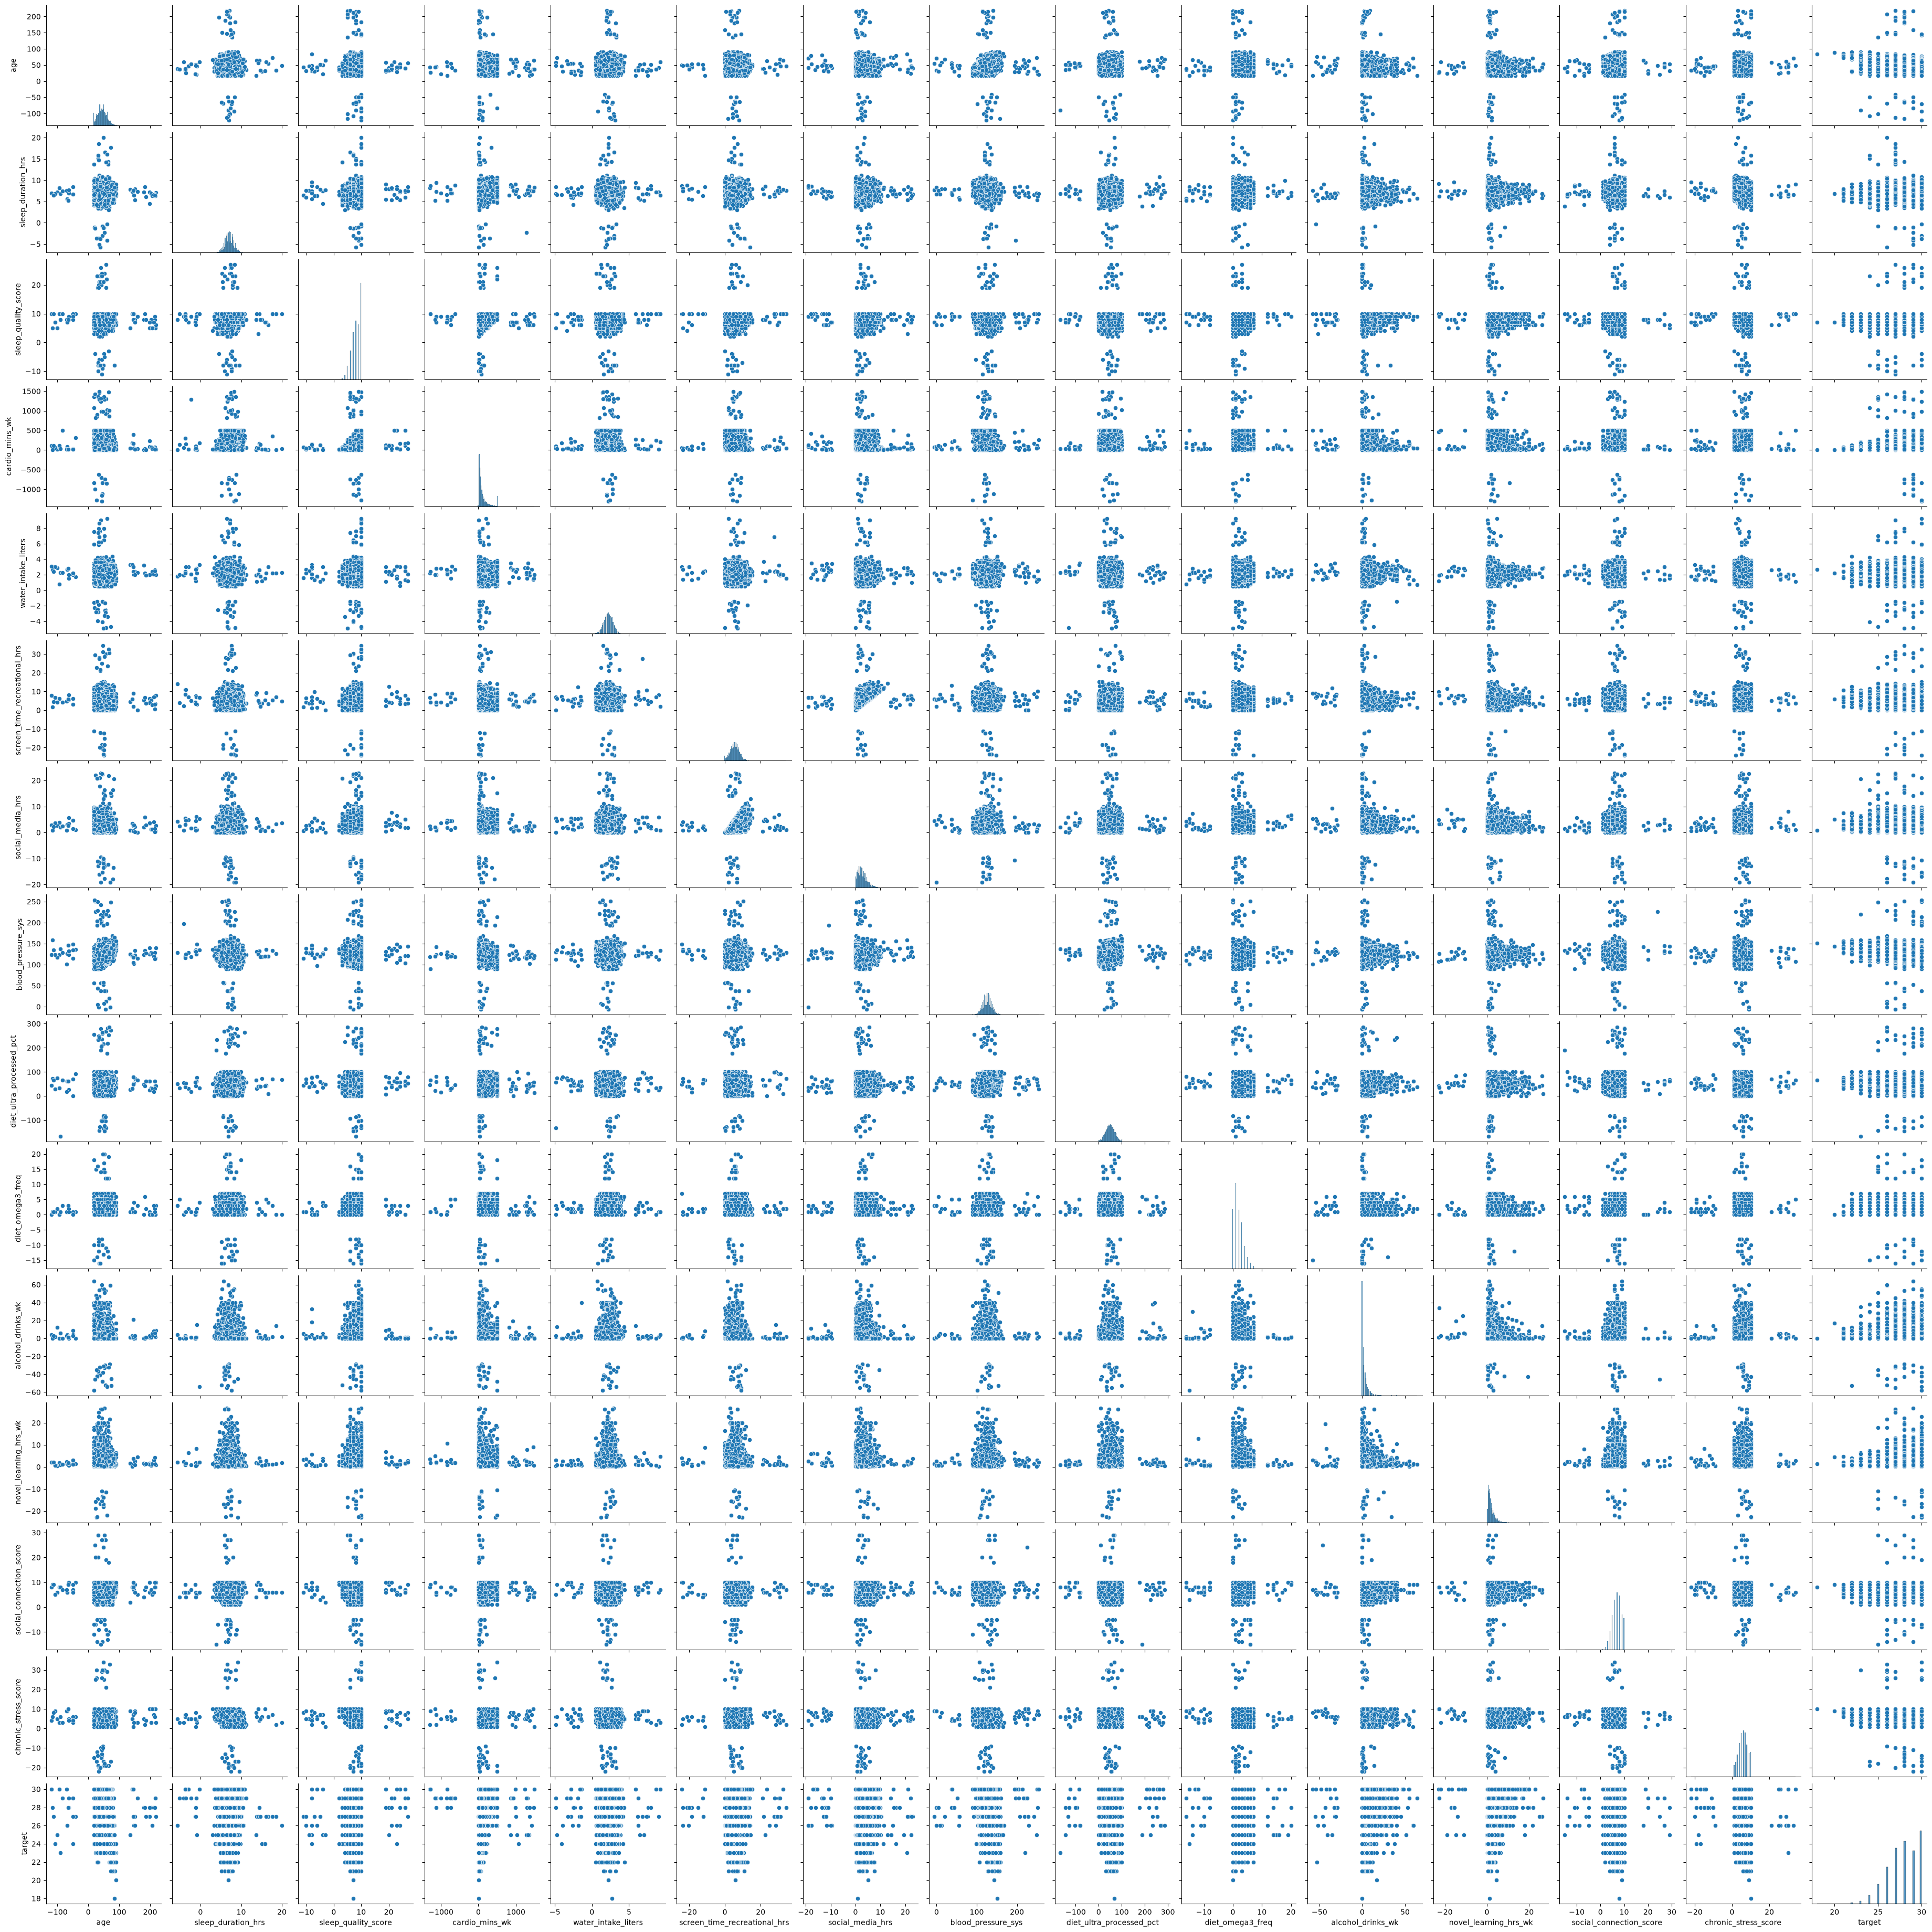

In [10]:
# Use 2% of the data, because pairplot is slow with large datasets
df_subset = df_train.sample(frac=0.02, random_state=42)

sns.pairplot(df_subset)
plt.show()

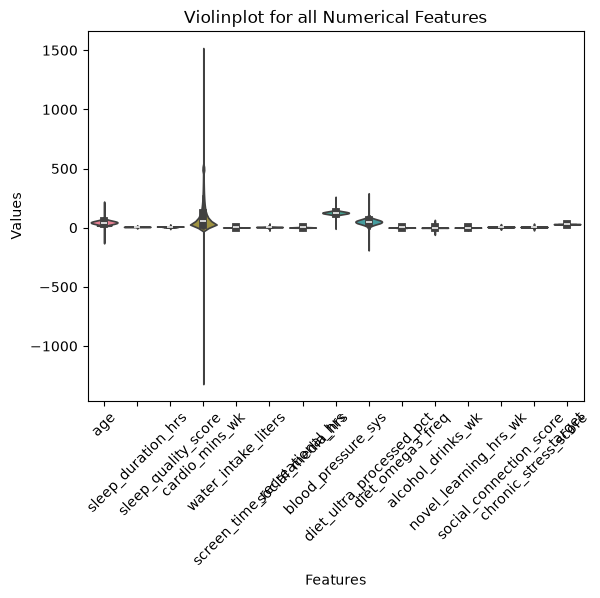

In [11]:
# Plot violinplot of all features
sns.violinplot(data=df_train.drop(columns= "smoking_status"))

plt.title("Violinplot for all Numerical Features")
plt.ylabel("Values")
plt.xlabel("Features")
plt.xticks(rotation=45)
plt.show()

_From initial inspection and the knowledge we have about these features, it seems that these features might be highly correlated. We will examine this using the correlation matrix._

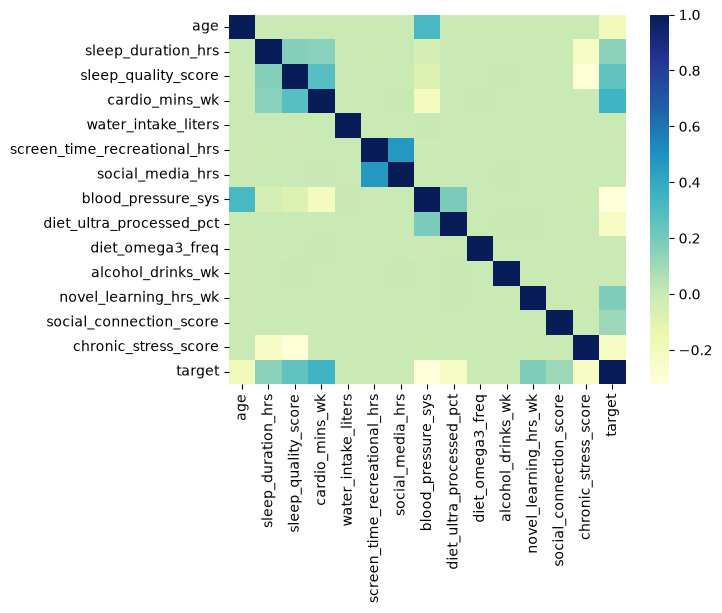

,age,sleep_duration_hrs,sleep_quality_score,cardio_mins_wk,water_intake_liters,screen_time_recreational_hrs,social_media_hrs,blood_pressure_sys,diet_ultra_processed_pct,diet_omega3_freq,alcohol_drinks_wk,novel_learning_hrs_wk,social_connection_score,chronic_stress_score,target
age,1.000000,-0.001497,0.000127,0.000126,0.002476,0.000933,0.001017,0.319365,-0.002433,0.002407,0.001057,-0.000580,-0.000365,-0.000877,-0.196137
sleep_duration_hrs,-0.001497,1.000000,0.160733,0.150276,0.001133,-0.003036,0.001094,-0.047858,0.002468,0.000117,-0.000035,0.000159,-0.001289,-0.226417,0.147185
sleep_quality_score,0.000127,0.160733,1.000000,0.278432,0.001210,0.000224,0.000918,-0.085640,0.001237,-0.001388,0.002959,0.001849,-0.002194,-0.310851,0.255571
cardio_mins_wk,0.000126,0.150276,0.278432,1.000000,-0.000994,0.000747,0.004236,-0.221964,0.001438,0.003179,-0.001225,-0.001402,-0.000477,-0.001211,0.345582
water_intake_liters,0.002476,0.001133,0.001210,-0.000994,1.000000,0.000862,-0.000930,0.004700,0.001411,-0.000395,0.000902,0.000914,-0.000483,-0.001644,-0.001405
screen_time_recreational_hrs,0.000933,-0.003036,0.000224,0.000747,0.000862,1.000000,0.472924,0.000476,-0.002001,0.002246,0.000742,0.000719,-0.001570,0.000930,0.001204
social_media_hrs,0.001017,0.001094,0.000918,0.004236,-0.000930,0.472924,1.000000,-0.001202,-0.000061,0.001442,0.003262,0.000986,-0.000465,-0.000372,0.001909
blood_pressure_sys,0.319365,-0.047858,-0.085640,-0.221964,0.004700,0.000476,-0.001202,1.000000,0.184105,-0.000293,0.000726,0.001805,0.001879,-0.004803,-0.322737
diet_ultra_processed_pct,-0.002433,0.002468,0.001237,0.001438,0.001411,-0.002001,-0.000061,0.184105,1.000000,-0.002437,0.003466,0.003749,-0.001175,-0.001849,-0.226910
diet_omega3_freq,0.002407,0.000117,-0.001388,0.003179,-0.000395,0.002246,0.001442,-0.000293,-0.002437,1.000000,-0.000216,0.000626,-0.002219,0.000863,-0.000449


In [12]:
# Compute correlation matrix
co_mtx = df_train.corr(numeric_only=True)

# Plot correlation heatmap
sns.heatmap(co_mtx, cmap="YlGnBu", annot=False)

# Display heatmap
plt.show()

# Show correlation matrix
co_mtx

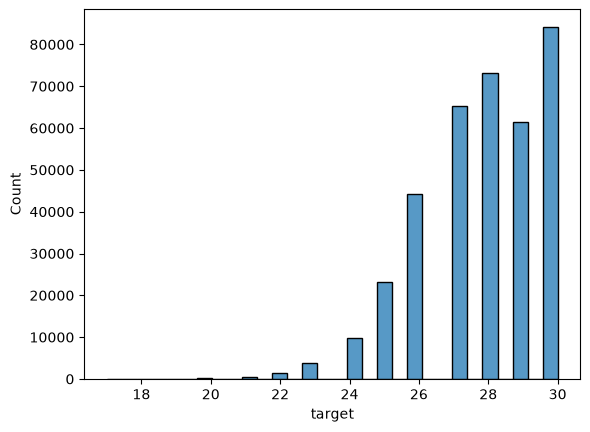

In [13]:
sns.histplot(df_train["target"], bins=30)
plt.show()

_SOME CONLCUSION FROM THE DATA EXPLORATION_

### Data cleaning

Check for duplicates in the data

In [14]:
df_train.duplicated().sum()

np.int64(17500)

Drop duplicates

In [15]:
df_train = df_train.drop_duplicates()

Check for Nan values

In [16]:
df_train.isna().sum()

age                             20803
sleep_duration_hrs              25892
sleep_quality_score              9315
cardio_mins_wk                  11553
water_intake_liters              8100
screen_time_recreational_hrs    27306
social_media_hrs                 5047
blood_pressure_sys               9210
diet_ultra_processed_pct        12667
diet_omega3_freq                21457
smoking_status                  24112
alcohol_drinks_wk               19600
novel_learning_hrs_wk           25419
social_connection_score         23666
chronic_stress_score            17127
target                              0
dtype: int64

Drop Nan values. We will not replace these valeus with the median or the mean since we have a large dataset. 

In [17]:
df_train = df_train.dropna()


Check for outliers

In [18]:
# Numerical columns
num_cols = df_train.select_dtypes(include=np.number).columns

# Delete outliers that are more than 4 standard deviations away from the mean
for col in num_cols:
    mean = df_train[col].mean()
    std = df_train[col].std()
    df_train = df_train[(df_train[col] >= mean - 4 * std) & (df_train[col] <= mean + 4 * std)]


### Data exploration and visualization after cleaning

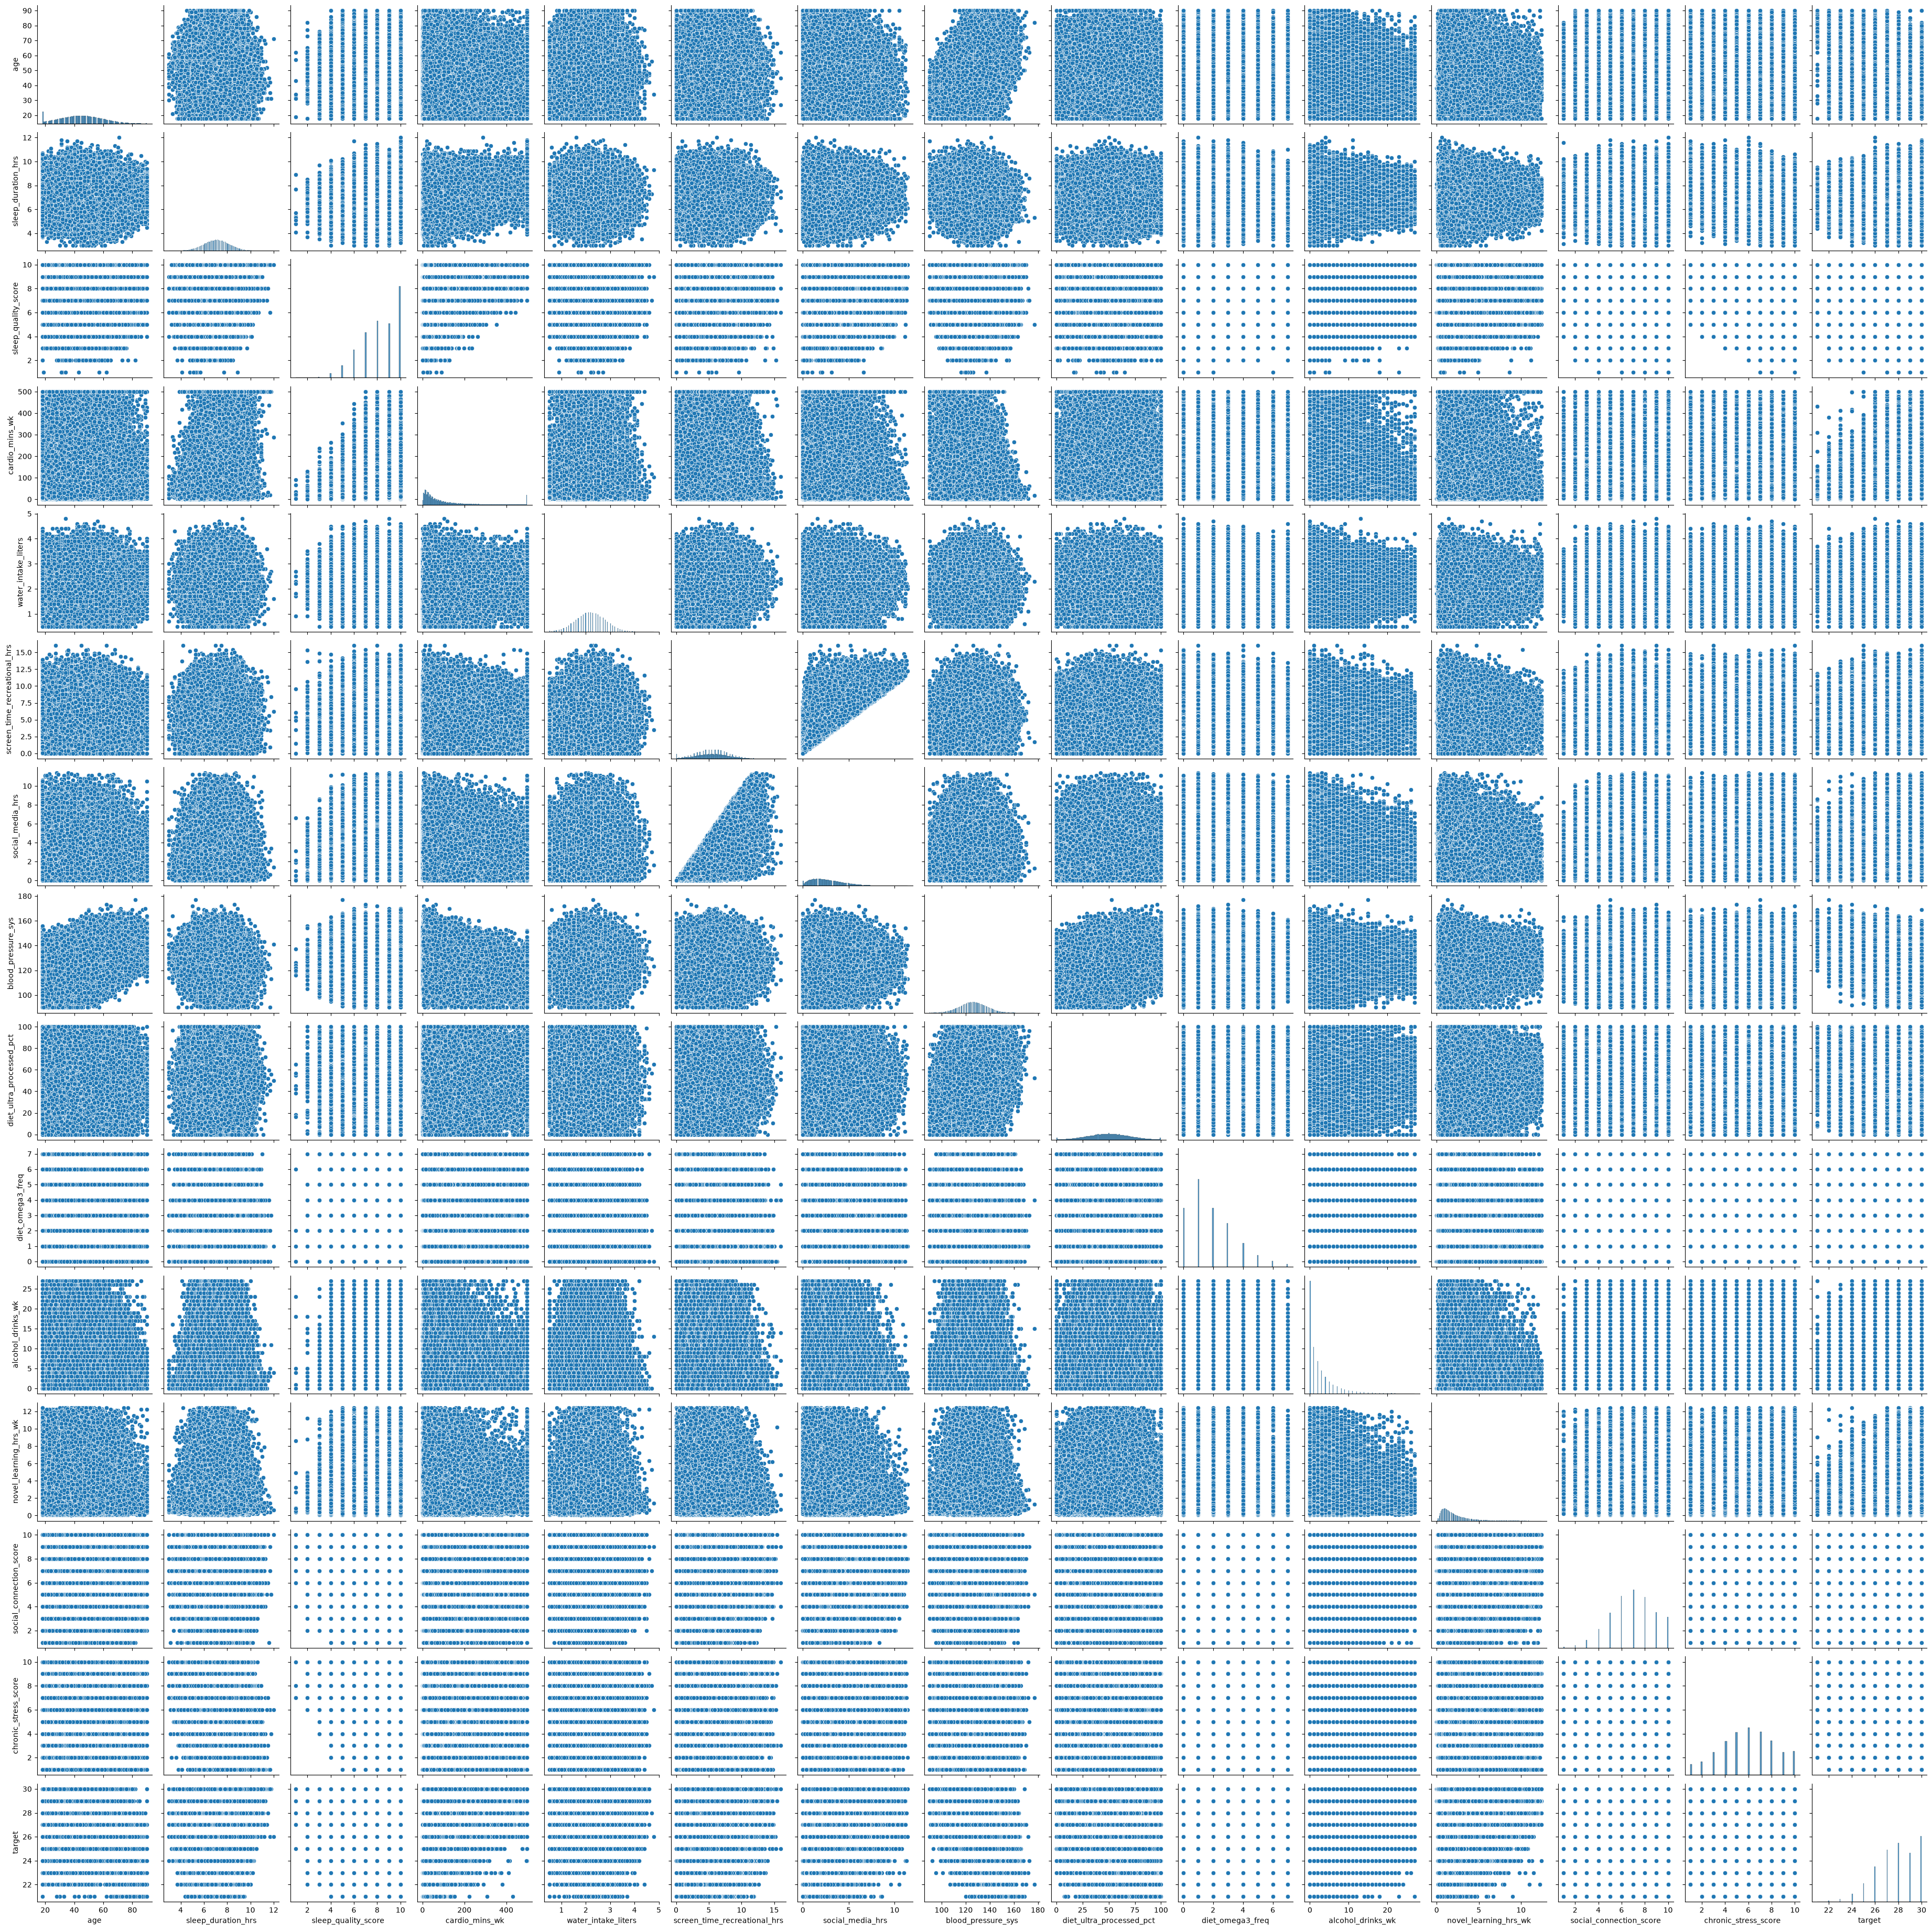

In [19]:
sns.pairplot(df_train)
plt.show()

### Data preprocessing

Standardize the data

In [24]:
# Drop the "id" column from the test datasets
df_test = df_test.drop(columns=["id"])

In [27]:
# Features
X_train = df_train.drop(columns="target")
X_test = df_test.copy()

# Target
y_train = df_train["target"]

# Scale features
x_scaler = StandardScaler()
X_train = x_scaler.fit_transform(X_train.drop(columns="smoking_status"))
X_test = x_scaler.transform(X_test.drop(columns="smoking_status"))

# Scale target (if you really want to)
y_scaler = StandardScaler()
y_train = y_scaler.fit_transform(y_train.to_frame()).ravel()

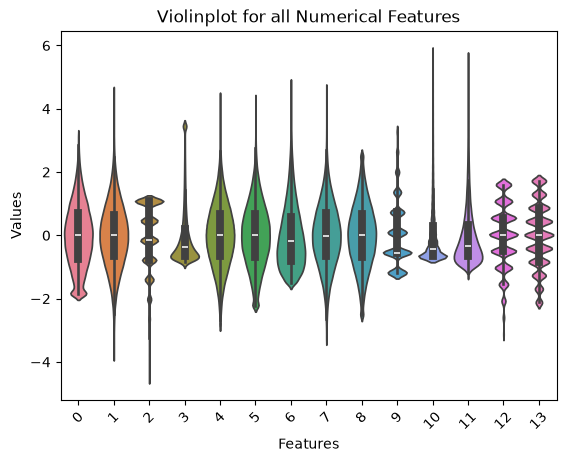

In [29]:
# Plot violinplot of all features
sns.violinplot(X_train)

plt.title("Violinplot for all Numerical Features")
plt.ylabel("Values")
plt.xlabel("Features")
plt.xticks(rotation=45)
plt.show()

### Evaluating different models/hyperparameters (using cross-validation)

### Kaggle submission (with prediction and result on the test set)